# ***`WINE CLASSIFICATION`***

# **This is a model that predicts what class of grape a wine came from.**

### **Complete Project workflow**

- Load the Wine dataset
- Exploration and understanding of the data
- Check for missing values and duplicates
- Split data into training, validation, and test sets
- Standardize the features
- Convert data into PyTorch tensors
- Create DataLoaders
- Build the multiclass neural network
Train and validate the model

- valuate on the test set

- Tune hyperparameters if needed

- Save the model and scaler

1. Load the data

from sklearn.datasets import load_wine
data = load_wine()

2. Split, scale and convert to tensors, the same way we did in class.

3. We now have 3 classes instead of 2, so change these four parts:

Last layer outputs 3 values: nn.Linear(16, 3)
Loss: nn.CrossEntropyLoss()
Targets are whole numbers, and you do not reshape them: torch.tensor(y_tr, dtype=torch.long)
Predictions: preds = torch.argmax(logits, dim=1)

4. Train the model, print the loss for each epoch and report your test accuracy.

In [1]:
# import the necessary libraries

import pandas as pd
import numpy as np

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

import matplotlib.pyplot as plt

In [2]:
# activate random seed
torch.manual_seed(42)

Load Data

In [3]:
# load data

data =  load_wine()
X= data.data
y= data.target

In [4]:
print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("Feature names:")
print(data.feature_names)

print("Target classes:")
print(data.target_names)

Feature shape: (178, 13)
Target shape: (178,)
Feature names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target classes:
['class_0' 'class_1' 'class_2']


In [5]:
# view the data features

data.data

array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
        1.185e+03],
       ...,
       [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
        8.350e+02],
       [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
        8.400e+02],
       [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
        5.600e+02]])

In [6]:
# convert to pandas DataFrame

data= load_wine(as_frame= True)
df = data.frame

Explore the Data

In [7]:
# view the df
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [8]:
# view the shape
print("Dataset shape:", df.shape)

# Examine trheir datatypes
print("\nData types:")
print(df.dtypes)

# Check for mising values
print("\nMissing values:")
print(df.isnull().sum().sum())

# Check for duplicates
print("\nDuplicate rows:")
print(df.duplicated().sum())

# View the classes in the target column
print("\nClass distribution:")
print(df["target"].value_counts().sort_index())

Dataset shape: (178, 14)

Data types:
alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
target                            int64
dtype: object

Missing values:
0

Duplicate rows:
0

Class distribution:
target
0    59
1    71
2    48
Name: count, dtype: int64


In [9]:
# view the data info

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  targe

In [10]:
# View the data statistical description

df.describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258,0.938202
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474,0.775035
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000,0.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000,0.000000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000,1.000000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000,2.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000,2.000000


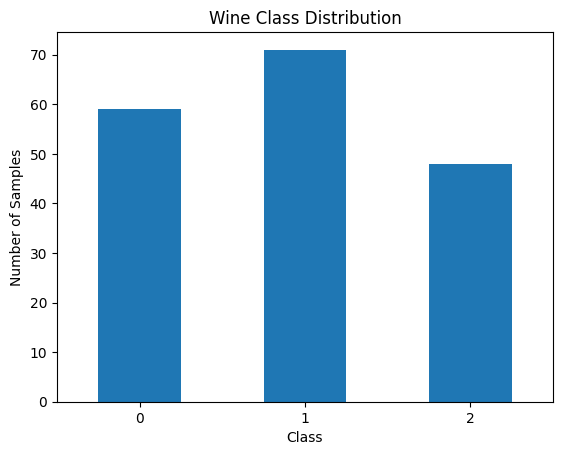

In [11]:
df["target"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Wine Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Samples")
plt.show()

Split Data

The data will be splited into three subsets:
- Training set
- Validation set
- Testing set

In [12]:
# split the data into train and temporary set

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size= 0.3, random_state=42, stratify= y)

In [13]:
# split data into Validation and Testing

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size= 0.5, random_state=42, stratify= y_temp)

In [14]:
# View the Features shape

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

print("\nTraining class counts:")
print(pd.Series(y_train).value_counts().sort_index())

Training set: (124, 13)
Validation set: (27, 13)
Testing set: (27, 13)

Training class counts:
0    41
1    50
2    33
Name: count, dtype: int64


Data Preparation for Modeling

In [15]:
# Scale the features using StandScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
X_val = scaler.transform(X_val)

In [16]:
# Convert the data to tensors because pytorch don't work no other type but tensor type.
X_train = torch.tensor(X_train, dtype= torch.float32)
X_test = torch.tensor(X_test, dtype= torch.float32)
X_val = torch.tensor(X_val, dtype= torch.float32)

y_train = torch.tensor(y_train, dtype= torch.long)
y_test = torch.tensor(y_test, dtype= torch.long)
y_val = torch.tensor(y_val, dtype= torch.long)

In [17]:
# Verify the shapes

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: torch.Size([124, 13])
y_train: torch.Size([124])
X_val: torch.Size([27, 13])
y_val: torch.Size([27])
X_test: torch.Size([27, 13])
y_test: torch.Size([27])


In [18]:
# prepare the training data

train_data = TensorDataset(X_train, y_train) # Combines each training input with its correct target
train_dl = DataLoader( # Delivers the data to the model in batches
    train_data, # introduce the trainig data
    batch_size= 32, # Specifies how many samples to deliver per batch
    shuffle = True # Randomizes the sample order each epoch
)

In [19]:
# prepare the Validation data

val_data = TensorDataset(X_val, y_val) # Combines each validation input with its correct target
val_dl = DataLoader( # Delivers the data to the model in batches
    val_data, # introduce the Validation data
    batch_size= 32,
    shuffle= True
)

In [20]:
# Check the number of the training batches

print("Training batches:", len(train_dl))
print("Validation batches:", len(val_dl))

Training batches: 4
Validation batches: 1


Build the Multi-Class Neural Network

In [21]:
# Use a python class to build and train the model

class WineNet(nn.Module):
  def __init__(self, n_in):
    super().__init__()

    self.net= nn.Sequential(
        nn.Linear(n_in, 32),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(32, 16),
        nn.ReLU(),
        nn.Dropout(0.2),

        nn.Linear(16, 3)
    )

  def forward(self, x):
    return self.net(x)



In [22]:
# Create the model

device= "cuda" if torch.cuda.is_available() else "cpu"

model= WineNet(X_train.shape[1]).to(device)

In [23]:
# View the model and device
print(model)
print("Device:", device)

WineNet(
  (net): Sequential(
    (0): Linear(in_features=13, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=32, out_features=16, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=16, out_features=3, bias=True)
  )
)
Device: cuda


In [24]:
# Define the loss function and optimizer

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr= 0.001)

In [25]:
import copy

num_epochs= 100 # train up to 100 epochs

best_val_loss = float("inf")
best_state = None # Keep the best performing model state

train_losses = [] # empty list for the training losses
val_losses = [] # empty list for the validation losses

Model Training & Validation

In [26]:
# The training phase
for epoch in range(num_epochs):
  model.train()
  training_running_loss = 0.0

  for xb, yb in train_dl:
    xb, yb = xb.to(device), yb.to(device)

    optimizer.zero_grad()

    loss = criterion(model(xb), yb)

    loss.backward()
    optimizer.step()

    training_running_loss += loss.item()
  avg_train_loss= training_running_loss / len(train_dl)
  train_losses.append(avg_train_loss)

  # Validation phase
  model.eval()
  val_running_loss = 0.0

  with torch.no_grad():
      for xb, yb in val_dl:
          xb, yb = xb.to(device), yb.to(device)

          outputs = model(xb)
          loss = criterion(outputs, yb)

          val_running_loss += loss.item()

  avg_val_loss = val_running_loss / len(val_dl)
  val_losses.append(avg_val_loss)

In [27]:
# keep the best model with the lowest validation loss

if avg_val_loss < best_val_loss:
  best_val_loss = avg_val_loss
  best_state = copy.deepcopy(model.state_dict())

if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch + 1:3d}/{num_epochs} | "
            f"Train Loss: {avg_train_loss:.4f} | "
            f"Val Loss: {avg_val_loss:.4f}"
        )

# Restore the best validation model
model.load_state_dict(best_state)

Epoch 100/100 | Train Loss: 0.0349 | Val Loss: 0.0480


<All keys matched successfully>

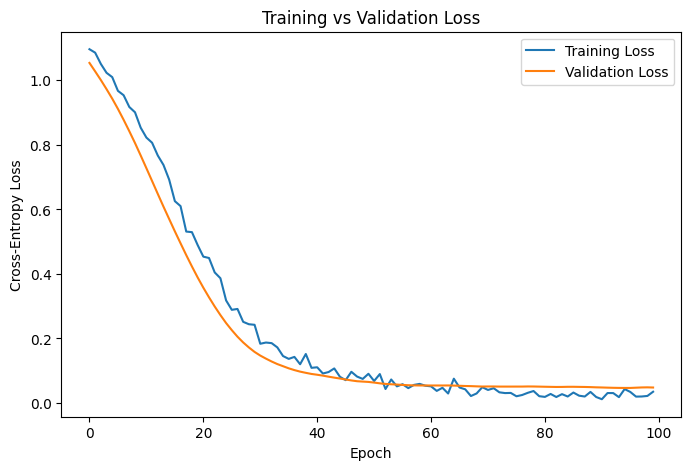

In [28]:
# Visualize the training and Validation loss

plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.show()

In [29]:
print("Training losses:", len(train_losses))
print("Validation losses:", len(val_losses))

print("Training loss sample:", train_losses[:5])
print("Validation loss sample:", val_losses[:5])

Training losses: 100
Validation losses: 100
Training loss sample: [1.0965106189250946, 1.0858465433120728, 1.050923615694046, 1.0233886986970901, 1.0100304335355759]
Validation loss sample: [1.0540529489517212, 1.0278304815292358, 1.0010278224945068, 0.972737193107605, 0.9432544112205505]


Model Evaluation

In [30]:
model.eval()

with torch.no_grad():
  X_test_device = X_test.to(device)

  logits = model(X_test_device)
  preds= torch.argmax(logits, dim=1)

  y_true = y_test.cpu().numpy()
  y_pred = preds.cpu().numpy()



In [31]:
# Calculatee the evaluation metrics

accuracy = accuracy_score(y_true, y_pred)

print(f"Test Accuracy: {accuracy:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2],
        target_names=data.target_names,
        zero_division=0
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, y_pred, labels=[0, 1, 2]))



Test Accuracy: 0.96%

Classification Report:
              precision    recall  f1-score   support

     class_0       1.00      1.00      1.00         9
     class_1       0.92      1.00      0.96        11
     class_2       1.00      0.86      0.92         7

    accuracy                           0.96        27
   macro avg       0.97      0.95      0.96        27
weighted avg       0.97      0.96      0.96        27


Confusion Matrix:
[[ 9  0  0]
 [ 0 11  0]
 [ 0  1  6]]


Save Model and Scaler

In [32]:
import joblib

torch.save(model.state_dict(), "wine_model.pth")

joblib.dump(scaler, "wine_scaler.pkl")

['wine_scaler.pkl']